
Top result across all runs:
File: F:\\Desktop\\QAOA 5.08.25\\Ligand Novobiocin February\\Iterations\\3H_1A_0D-NEW2\results_3H_1A_0D-NEW2_with_4_features_iter_3.csv
Bitstring: 1000000100000010000001000
Probability: 0.84375
Ligand features: ['A1', 'H15', 'H16', 'H17']
Protein features: ['A1', 'H2', 'H3', 'H4']

How often ligand's features in top-bitstrings:
A1: 1.00
H15: 1.00
H16: 1.00
H17: 1.00


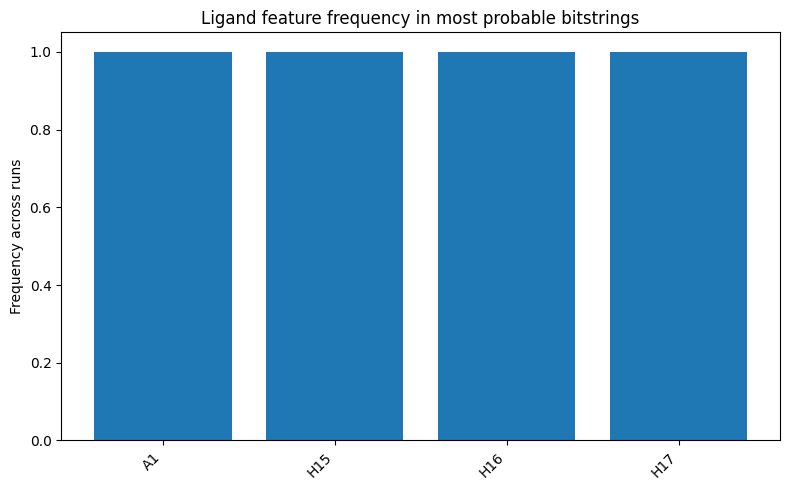

In [1]:
import pandas as pd
import glob
from collections import Counter
import ast
import matplotlib.pyplot as plt

# CSV
files = glob.glob(r"F:\\Desktop\\QAOA 5.08.25\\Ligand Novobiocin February\\Iterations\\3H_1A_0D-NEW2\\*.csv")

all_selected_ligand = []
top_probs = []
all_rows = []   # collect all rows across all files

for f in files:
    df = pd.read_csv(f)
    df["__file__"] = f  # keep track of file
    all_rows.append(df)

    # top row per file (your current logic)
    top_row = df.loc[df["Probability"].idxmax()]
    ligands = ast.literal_eval(top_row["Selected in the Ligand"])
    all_selected_ligand.extend(ligands)
    top_probs.append(top_row["Probability"])

# concatenate everything
all_df = pd.concat(all_rows, ignore_index=True)

# Global max probability
global_top = all_df.loc[all_df["Probability"].idxmax()]
print("\nTop result across all runs:")
print("File:", global_top["__file__"])
print("Bitstring:", global_top["Bitstring"])
print("Probability:", global_top["Probability"])
print("Ligand features:", global_top["Selected in the Ligand"])
print("Protein features:", global_top["Selected in the Protein"])

# frequencies of ligand features
counts = Counter(all_selected_ligand)
total_runs = len(files)
freq = {k: v/total_runs for k, v in counts.items()}

print("\nHow often ligand's features in top-bitstrings:")
for feat, fval in freq.items():
    print(f"{feat}: {fval:.2f}")

plt.figure(figsize=(8, 5))
plt.bar(freq.keys(), freq.values())
plt.xticks(rotation=45, ha="right")
plt.ylabel("Frequency across runs")
plt.title("Ligand feature frequency in most probable bitstrings")
plt.tight_layout()
plt.show()
